In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import h5py

from pathlib import Path

from skimage.transform import resize

from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_class_weight

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers


# Reproducibility
SEED = 42

np.random.seed(SEED)
tf.random.set_seed(SEED)


# Paths
DATA_ROOT = Path("../data/raw")
RESULTS_ROOT = Path("../results")

RESULTS_ROOT.mkdir(
    parents=True,
    exist_ok=True
)

IMG_SIZE = 128

CLASS_NAMES = [
    "Glioma",
    "Meningioma",
    "Pituitary"
]

print("TensorFlow:", tf.__version__)
print("Image size:", IMG_SIZE)

/Users/harshitabhardwaj/Desktop/Brain_Tumor_Detection/.venv/lib/python3.9/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


TensorFlow: 2.20.0
Image size: 128


In [8]:
mat_files = sorted(
    p for p in DATA_ROOT.rglob("*.mat")
    if p.name.lower() != "cvind.mat"
)

print(f"MAT files found: {len(mat_files)}")

MAT files found: 3064


In [9]:
def load_figshare_data(mat_files):
    images = []
    labels = []
    patient_ids = []

    for mat_file in mat_files:

        with h5py.File(mat_file, "r") as f:

            cjdata = f["cjdata"]

            image = np.asarray(
                cjdata["image"],
                dtype=np.float32
            )

            label = int(
                np.asarray(
                    cjdata["label"]
                ).squeeze()
            )

            pid_codes = np.asarray(
                cjdata["PID"]
            ).reshape(-1)

            patient_id = "".join(
                chr(int(code))
                for code in pid_codes
            )

            images.append(image)
            labels.append(label)
            patient_ids.append(patient_id)

    return (
        images,
        np.asarray(labels, dtype=np.int64),
        np.asarray(patient_ids)
    )


images, labels, patient_ids = load_figshare_data(
    mat_files
)

print("Images:", len(images))
print("Labels:", len(labels))
print("Patients:", len(np.unique(patient_ids)))

Images: 3064
Labels: 3064
Patients: 233


In [10]:
X_images = np.empty(
    (len(images), IMG_SIZE, IMG_SIZE),
    dtype=np.float32
)

for i, image in enumerate(images):

    resized = resize(
        image,
        (IMG_SIZE, IMG_SIZE),
        anti_aliasing=True,
        preserve_range=True
    ).astype(np.float32)

    image_min = resized.min()
    image_max = resized.max()

    if image_max > image_min:
        resized = (
            resized - image_min
        ) / (
            image_max - image_min
        )
    else:
        resized = np.zeros_like(resized)

    X_images[i] = resized


y = labels.copy()

print("Input shape:", X_images.shape)
print("Label shape:", y.shape)

Input shape: (3064, 128, 128)
Label shape: (3064,)


In [11]:
gss = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=SEED
)

train_idx, test_idx = next(
    gss.split(
        X_images,
        y,
        groups=patient_ids
    )
)


X_train_images = X_images[train_idx]
X_test_images = X_images[test_idx]

y_train = y[train_idx]
y_test = y[test_idx]

pid_train = patient_ids[train_idx]
pid_test = patient_ids[test_idx]


print("Training samples:", len(X_train_images))
print("Testing samples :", len(X_test_images))

print(
    "Patient overlap:",
    len(
        set(pid_train) &
        set(pid_test)
    )
)

Training samples: 2452
Testing samples : 612
Patient overlap: 0


In [12]:
gss_val = GroupShuffleSplit(
    n_splits=1,
    test_size=0.15,
    random_state=SEED
)

train_inner_idx, val_idx = next(
    gss_val.split(
        X_train_images,
        y_train,
        groups=pid_train
    )
)


X_train_final = X_train_images[
    train_inner_idx
]

X_val = X_train_images[
    val_idx
]

y_train_final = y_train[
    train_inner_idx
]

y_val = y_train[
    val_idx
]


print("Train:", X_train_final.shape)
print("Validation:", X_val.shape)
print("Test:", X_test_images.shape)

Train: (2051, 128, 128)
Validation: (401, 128, 128)
Test: (612, 128, 128)


In [13]:
X_train_flat = X_train_final.reshape(
    X_train_final.shape[0],
    -1
)

X_val_flat = X_val.reshape(
    X_val.shape[0],
    -1
)

X_test_flat = X_test_images.reshape(
    X_test_images.shape[0],
    -1
)


scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(
    X_train_flat
)

X_val_scaled = scaler.transform(
    X_val_flat
)

X_test_scaled = scaler.transform(
    X_test_flat
)


print("Train:", X_train_scaled.shape)
print("Validation:", X_val_scaled.shape)
print("Test:", X_test_scaled.shape)

Train: (2051, 16384)
Validation: (401, 16384)
Test: (612, 16384)


In [14]:
y_train_ann = y_train_final - 1
y_val_ann = y_val - 1
y_test_ann = y_test - 1


classes = np.unique(y_train_ann)

class_weights_array = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train_ann
)

ann_class_weights = dict(
    zip(
        classes,
        class_weights_array
    )
)

print("Classes:", classes)
print("Class weights:", ann_class_weights)

Classes: [0 1 2]
Class weights: {np.int64(0): np.float64(1.2340553549939832), np.int64(1): np.float64(0.687793427230047), np.int64(2): np.float64(1.3591782637508283)}


In [15]:
ann_v2 = keras.Sequential(
    [
        keras.Input(
            shape=(X_train_scaled.shape[1],)
        ),

        layers.Dense(
            256,
            kernel_regularizer=regularizers.l2(1e-4)
        ),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.Dropout(0.50),

        layers.Dense(
            128,
            kernel_regularizer=regularizers.l2(1e-4)
        ),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.Dropout(0.40),

        layers.Dense(
            64,
            kernel_regularizer=regularizers.l2(1e-4)
        ),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.Dropout(0.30),

        layers.Dense(
            3,
            activation="softmax"
        )
    ],
    name="Brain_Tumor_ANN_v2"
)

ann_v2.summary()

Model: "Brain_Tumor_ANN_v2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 256)            │     4,194,560 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,237,699 (16.17 MB)

 Trainable params: 4,236,803 (16.16 MB)

 Non-trainable params: 896 (3.50 KB)

In [16]:
ann_v2.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=5e-4
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [17]:
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=12,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=4,
    min_lr=1e-6,
    verbose=1
)

checkpoint = keras.callbacks.ModelCheckpoint(
    filepath=str(
        RESULTS_ROOT / "best_ann_v2.keras"
    ),
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

In [18]:
history_v2 = ann_v2.fit(
    X_train_scaled,
    y_train_ann,

    validation_data=(
        X_val_scaled,
        y_val_ann
    ),

    epochs=100,
    batch_size=32,

    class_weight=ann_class_weights,

    callbacks=[
        early_stopping,
        reduce_lr,
        checkpoint
    ],

    verbose=1
)

Epoch 1/100
61/65 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.5160 - loss: 1.0405
Epoch 1: val_loss improved from inf to 0.49143, saving model to ../results/best_ann_v2.keras
65/65 ━━━━━━━━━━━━━━━━━━━━ 3s 17ms/step - accuracy: 0.5234 - loss: 1.0267 - val_accuracy: 0.8329 - val_loss: 0.4914 - learning_rate: 5.0000e-04
Epoch 2/100
64/65 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.7371 - loss: 0.6505
Epoch 2: val_loss improved from 0.49143 to 0.39709, saving model to ../results/best_ann_v2.keras
65/65 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - accuracy: 0.7377 - loss: 0.6499 - val_accuracy: 0.8678 - val_loss: 0.3971 - learning_rate: 5.0000e-04
Epoch 3/100
64/65 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.8147 - loss: 0.5076
Epoch 3: val_loss improved from 0.39709 to 0.39037, saving model to ../results/best_ann_v2.keras
65/65 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - accuracy: 0.8149 - loss: 0.5073 - val_accuracy: 0.8928 - val_loss: 0.3904 - learning_rate: 5.0000e-04
Epoch 4/100
65/65 ━━━━━

In [19]:
best_ann_v2 = keras.models.load_model(
    RESULTS_ROOT / "best_ann_v2.keras"
)

test_prob_v2 = best_ann_v2.predict(
    X_test_scaled,
    verbose=0
)

y_pred_v2 = np.argmax(
    test_prob_v2,
    axis=1
)


ann_v2_accuracy = accuracy_score(
    y_test_ann,
    y_pred_v2
)

ann_v2_precision = precision_score(
    y_test_ann,
    y_pred_v2,
    average="macro",
    zero_division=0
)

ann_v2_recall = recall_score(
    y_test_ann,
    y_pred_v2,
    average="macro",
    zero_division=0
)

ann_v2_f1 = f1_score(
    y_test_ann,
    y_pred_v2,
    average="macro",
    zero_division=0
)


print("========== ANN-v2 RESULTS ==========")
print(f"Accuracy        : {ann_v2_accuracy:.4f}")
print(f"Macro Precision : {ann_v2_precision:.4f}")
print(f"Macro Recall    : {ann_v2_recall:.4f}")
print(f"Macro F1        : {ann_v2_f1:.4f}")

========== ANN-v2 RESULTS ==========
Accuracy        : 0.8529
Macro Precision : 0.8169
Macro Recall    : 0.8350
Macro F1        : 0.8246


In [20]:
print(
    classification_report(
        y_test_ann,
        y_pred_v2,
        target_names=CLASS_NAMES,
        digits=4,
        zero_division=0
    )
)

              precision    recall  f1-score   support

      Glioma     0.6518    0.7449    0.6952        98
  Meningioma     0.8815    0.8264    0.8530       288
   Pituitary     0.9174    0.9336    0.9254       226

    accuracy                         0.8529       612
   macro avg     0.8169    0.8350    0.8246       612
weighted avg     0.8580    0.8529    0.8545       612



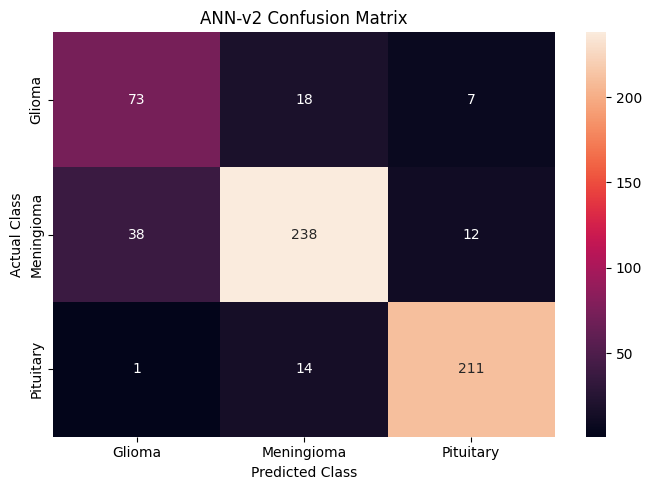

In [21]:
cm_v2 = confusion_matrix(
    y_test_ann,
    y_pred_v2
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_v2,
    annot=True,
    fmt="d",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("ANN-v2 Confusion Matrix")

plt.tight_layout()
plt.show()

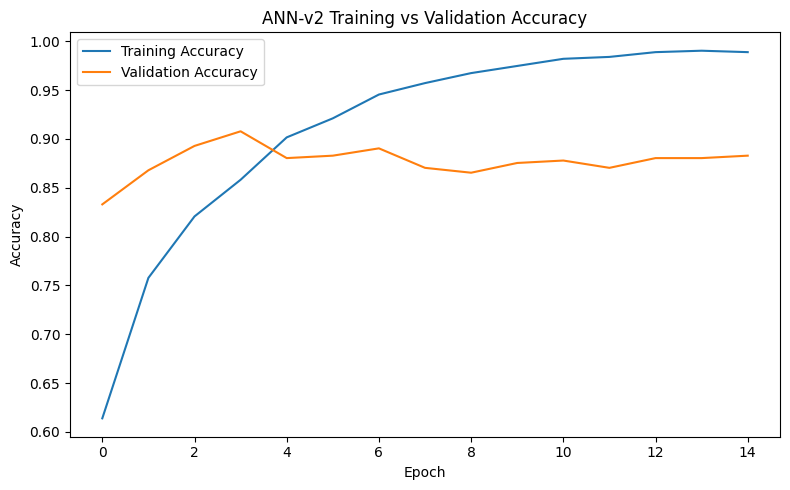

In [22]:
plt.figure(figsize=(8, 5))

plt.plot(
    history_v2.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history_v2.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title(
    "ANN-v2 Training vs Validation Accuracy"
)

plt.legend()
plt.tight_layout()
plt.show()

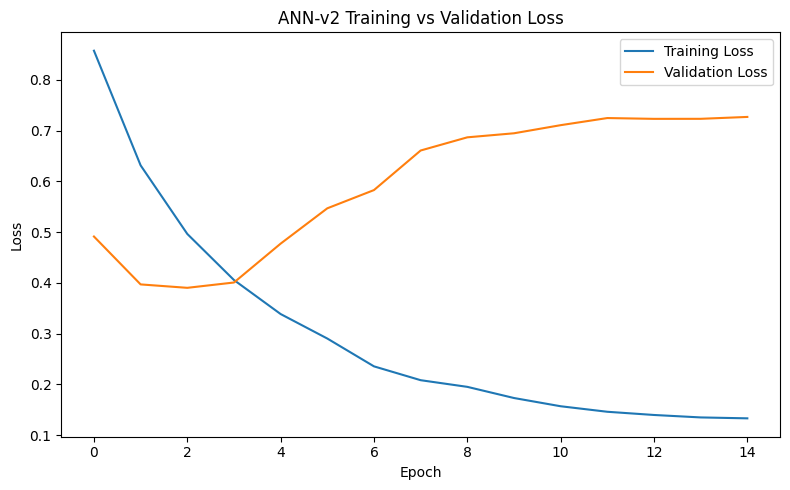

In [23]:
plt.figure(figsize=(8, 5))

plt.plot(
    history_v2.history["loss"],
    label="Training Loss"
)

plt.plot(
    history_v2.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title(
    "ANN-v2 Training vs Validation Loss"
)

plt.legend()
plt.tight_layout()
plt.show()

In [24]:
ann_v3 = keras.Sequential(
    [
        keras.Input(
            shape=(X_train_scaled.shape[1],)
        ),

        layers.Dense(
            256,
            kernel_regularizer=regularizers.l2(5e-5)
        ),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.Dropout(0.35),

        layers.Dense(
            128,
            kernel_regularizer=regularizers.l2(5e-5)
        ),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.Dropout(0.25),

        layers.Dense(
            64,
            kernel_regularizer=regularizers.l2(5e-5)
        ),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.Dropout(0.15),

        layers.Dense(
            3,
            activation="softmax"
        )
    ],
    name="Brain_Tumor_ANN_v3"
)

ann_v3.summary()

Model: "Brain_Tumor_ANN_v3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_4 (Dense)                 │ (None, 256)            │     4,194,560 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_5 (Activation)       │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,237,699 (16.17 MB)

 Trainable params: 4,236,803 (16.16 MB)

 Non-trainable params: 896 (3.50 KB)

In [25]:
ann_v3.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=3e-4
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [26]:
early_stopping_v3 = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True,
    verbose=1
)

reduce_lr_v3 = keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=1,
    min_lr=1e-6,
    verbose=1
)

checkpoint_v3 = keras.callbacks.ModelCheckpoint(
    filepath=str(
        RESULTS_ROOT / "best_ann_v3.keras"
    ),
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

In [27]:
history_v3 = ann_v3.fit(
    X_train_scaled,
    y_train_ann,
    validation_data=(
        X_val_scaled,
        y_val_ann
    ),
    epochs=30,
    batch_size=32,
    class_weight=ann_class_weights,
    callbacks=[
        early_stopping_v3,
        reduce_lr_v3,
        checkpoint_v3
    ],
    verbose=1
)

Epoch 1/30
62/65 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.5488 - loss: 0.8885
Epoch 1: val_loss improved from inf to 0.41931, saving model to ../results/best_ann_v3.keras
65/65 ━━━━━━━━━━━━━━━━━━━━ 3s 17ms/step - accuracy: 0.5551 - loss: 0.8782 - val_accuracy: 0.8304 - val_loss: 0.4193 - learning_rate: 3.0000e-04
Epoch 2/30
63/65 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.8055 - loss: 0.4904
Epoch 2: val_loss improved from 0.41931 to 0.40183, saving model to ../results/best_ann_v3.keras
65/65 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - accuracy: 0.8063 - loss: 0.4888 - val_accuracy: 0.8753 - val_loss: 0.4018 - learning_rate: 3.0000e-04
Epoch 3/30
63/65 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.8822 - loss: 0.3488
Epoch 3: ReduceLROnPlateau reducing learning rate to 0.0001500000071246177.

Epoch 3: val_loss did not improve from 0.40183
65/65 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - accuracy: 0.8829 - loss: 0.3474 - val_accuracy: 0.8878 - val_loss: 0.4560 - learning_rate: 3.0000e-04

In [28]:
best_ann_v3 = keras.models.load_model(
    RESULTS_ROOT / "best_ann_v3.keras"
)

test_prob_v3 = best_ann_v3.predict(
    X_test_scaled,
    verbose=0
)

y_pred_v3 = np.argmax(
    test_prob_v3,
    axis=1
)

In [29]:
ann_v3_accuracy = accuracy_score(
    y_test_ann,
    y_pred_v3
)

ann_v3_precision = precision_score(
    y_test_ann,
    y_pred_v3,
    average="macro",
    zero_division=0
)

ann_v3_recall = recall_score(
    y_test_ann,
    y_pred_v3,
    average="macro",
    zero_division=0
)

ann_v3_f1 = f1_score(
    y_test_ann,
    y_pred_v3,
    average="macro",
    zero_division=0
)


print("========== ANN-v3 RESULTS ==========")
print(f"Accuracy        : {ann_v3_accuracy:.4f}")
print(f"Macro Precision : {ann_v3_precision:.4f}")
print(f"Macro Recall    : {ann_v3_recall:.4f}")
print(f"Macro F1        : {ann_v3_f1:.4f}")

========== ANN-v3 RESULTS ==========
Accuracy        : 0.8399
Macro Precision : 0.8035
Macro Recall    : 0.8421
Macro F1        : 0.8125


In [30]:
print(
    classification_report(
        y_test_ann,
        y_pred_v3,
        target_names=CLASS_NAMES,
        digits=4,
        zero_division=0
    )
)

              precision    recall  f1-score   support

      Glioma     0.5714    0.8163    0.6723        98
  Meningioma     0.9404    0.7674    0.8451       288
   Pituitary     0.8987    0.9425    0.9201       226

    accuracy                         0.8399       612
   macro avg     0.8035    0.8421    0.8125       612
weighted avg     0.8659    0.8399    0.8451       612



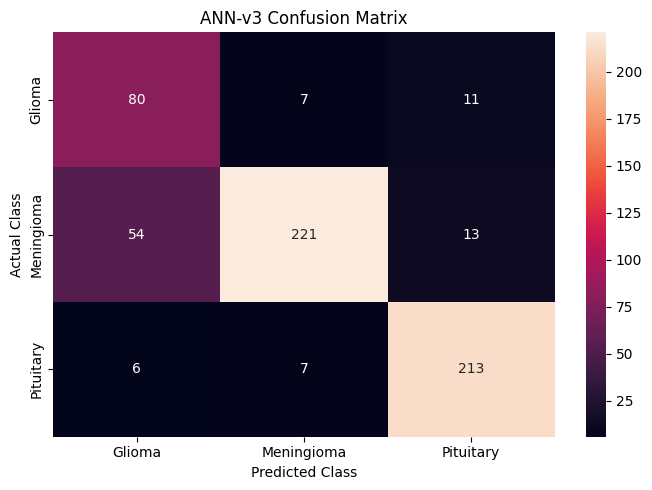

In [31]:
cm_v3 = confusion_matrix(
    y_test_ann,
    y_pred_v3
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_v3,
    annot=True,
    fmt="d",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("ANN-v3 Confusion Matrix")

plt.tight_layout()
plt.show()

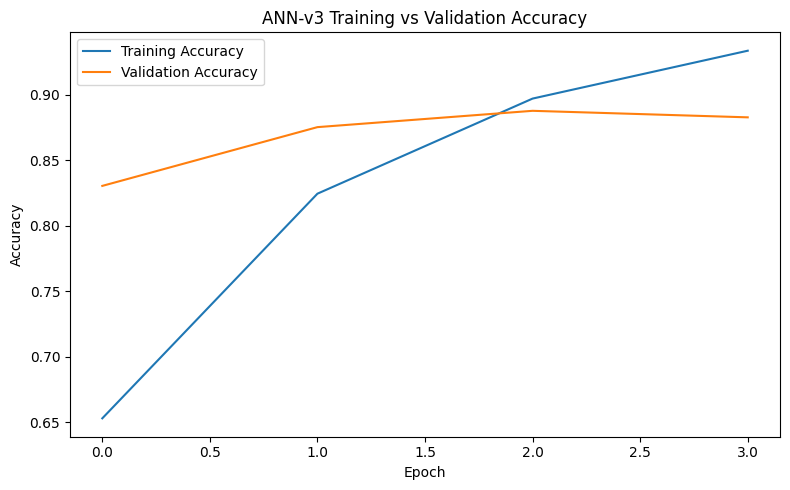

In [32]:
plt.figure(figsize=(8, 5))

plt.plot(
    history_v3.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history_v3.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("ANN-v3 Training vs Validation Accuracy")

plt.legend()
plt.tight_layout()
plt.show()

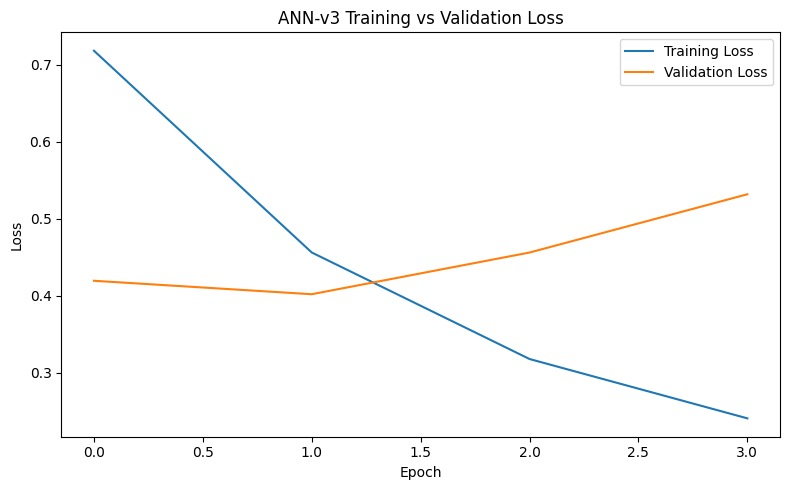

In [33]:
plt.figure(figsize=(8, 5))

plt.plot(
    history_v3.history["loss"],
    label="Training Loss"
)

plt.plot(
    history_v3.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("ANN-v3 Training vs Validation Loss")

plt.legend()
plt.tight_layout()
plt.show()

In [34]:
ann_comparison = pd.DataFrame({
    "Model": [
        "ANN-v1",
        "ANN-v2",
        "ANN-v3"
    ],

    "Accuracy": [
        0.8252,
        0.8007,
        ann_v3_accuracy
    ],

    "Macro Precision": [
        0.7896,
        0.7653,
        ann_v3_precision
    ],

    "Macro Recall": [
        0.7826,
        0.7986,
        ann_v3_recall
    ],

    "Macro F1": [
        0.7839,
        0.7732,
        ann_v3_f1
    ]
})

ann_comparison

,Model,Accuracy,Macro Precision,Macro Recall,Macro F1
0,ANN-v1,0.825200,0.789600,0.782600,0.783900
1,ANN-v2,0.800700,0.765300,0.798600,0.773200
2,ANN-v3,0.839869,0.803529,0.842055,0.812493


In [35]:
augmentation = keras.Sequential(
    [
        layers.RandomRotation(
            factor=0.03,
            fill_mode="nearest"
        ),
        layers.RandomTranslation(
            height_factor=0.05,
            width_factor=0.05,
            fill_mode="nearest"
        )
    ],
    name="MRI_Augmentation"
)


X_train_aug = np.empty_like(X_train_final)

for i in range(len(X_train_final)):
    image = X_train_final[i][..., np.newaxis]

    augmented = augmentation(
        image,
        training=True
    ).numpy().squeeze()

    X_train_aug[i] = augmented


# Original + augmented training samples
X_train_combined = np.concatenate(
    [
        X_train_final,
        X_train_aug
    ],
    axis=0
)

y_train_combined = np.concatenate(
    [
        y_train_final,
        y_train_final
    ],
    axis=0
)

print("Original training samples :", len(X_train_final))
print("Augmented training samples:", len(X_train_aug))
print("Combined training samples :", len(X_train_combined))

Original training samples : 2051
Augmented training samples: 2051
Combined training samples : 4102


In [36]:
X_train_v4_flat = X_train_combined.reshape(
    X_train_combined.shape[0],
    -1
)

X_val_v4_flat = X_val.reshape(
    X_val.shape[0],
    -1
)

X_test_v4_flat = X_test_images.reshape(
    X_test_images.shape[0],
    -1
)


scaler_v4 = StandardScaler()

X_train_v4_scaled = scaler_v4.fit_transform(
    X_train_v4_flat
)

X_val_v4_scaled = scaler_v4.transform(
    X_val_v4_flat
)

X_test_v4_scaled = scaler_v4.transform(
    X_test_v4_flat
)


print("Train:", X_train_v4_scaled.shape)
print("Validation:", X_val_v4_scaled.shape)
print("Test:", X_test_v4_scaled.shape)

Train: (4102, 16384)
Validation: (401, 16384)
Test: (612, 16384)


In [37]:
y_train_v4 = y_train_combined - 1
y_val_v4 = y_val - 1
y_test_v4 = y_test - 1


classes_v4 = np.unique(y_train_v4)

class_weights_v4 = compute_class_weight(
    class_weight="balanced",
    classes=classes_v4,
    y=y_train_v4
)

ann_v4_class_weights = dict(
    zip(
        classes_v4,
        class_weights_v4
    )
)

print("Class weights:", ann_v4_class_weights)

Class weights: {np.int64(0): np.float64(1.2340553549939832), np.int64(1): np.float64(0.687793427230047), np.int64(2): np.float64(1.3591782637508283)}


In [38]:
ann_v4 = keras.Sequential(
    [
        keras.Input(
            shape=(X_train_v4_scaled.shape[1],)
        ),

        layers.Dense(
            128,
            kernel_regularizer=regularizers.l2(1e-4)
        ),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.Dropout(0.30),

        layers.Dense(
            64,
            kernel_regularizer=regularizers.l2(1e-4)
        ),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.Dropout(0.25),

        layers.Dense(
            32,
            kernel_regularizer=regularizers.l2(1e-4)
        ),
        layers.Activation("relu"),
        layers.Dropout(0.15),

        layers.Dense(
            3,
            activation="softmax"
        )
    ],
    name="Brain_Tumor_ANN_v4"
)

ann_v4.summary()

Model: "Brain_Tumor_ANN_v4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_8 (Dense)                 │ (None, 128)            │     2,097,280 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_6 (Activation)       │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_7 (Activation)       │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_8 (Activation)       │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,108,483 (8.04 MB)

 Trainable params: 2,108,099 (8.04 MB)

 Non-trainable params: 384 (1.50 KB)

In [39]:
ann_v4.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=3e-4
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [40]:
early_stopping_v4 = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=4,
    restore_best_weights=True,
    verbose=1
)

reduce_lr_v4 = keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=1e-6,
    verbose=1
)

checkpoint_v4 = keras.callbacks.ModelCheckpoint(
    filepath=str(
        RESULTS_ROOT / "best_ann_v4.keras"
    ),
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

In [41]:
history_v4 = ann_v4.fit(
    X_train_v4_scaled,
    y_train_v4,

    validation_data=(
        X_val_v4_scaled,
        y_val_v4
    ),

    epochs=40,
    batch_size=32,

    class_weight=ann_v4_class_weights,

    callbacks=[
        early_stopping_v4,
        reduce_lr_v4,
        checkpoint_v4
    ],

    verbose=1
)

Epoch 1/40
121/129 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.5690 - loss: 0.9080
Epoch 1: val_loss improved from inf to 0.42011, saving model to ../results/best_ann_v4.keras
129/129 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.5741 - loss: 0.8997 - val_accuracy: 0.8504 - val_loss: 0.4201 - learning_rate: 3.0000e-04
Epoch 2/40
124/129 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7504 - loss: 0.5837
Epoch 2: val_loss improved from 0.42011 to 0.40052, saving model to ../results/best_ann_v4.keras
129/129 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.7507 - loss: 0.5830 - val_accuracy: 0.8903 - val_loss: 0.4005 - learning_rate: 3.0000e-04
Epoch 3/40
126/129 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7924 - loss: 0.4860
Epoch 3: val_loss improved from 0.40052 to 0.37063, saving model to ../results/best_ann_v4.keras
129/129 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.7927 - loss: 0.4857 - val_accuracy: 0.8753 - val_loss: 0.3706 - learning_rate: 3.0000e-04
Epoch 4/40
126/129 ━

In [42]:
history_v4 = ann_v4.fit(
    X_train_v4_scaled,
    y_train_v4,

    validation_data=(
        X_val_v4_scaled,
        y_val_v4
    ),

    epochs=40,
    batch_size=32,

    class_weight=ann_v4_class_weights,

    callbacks=[
        early_stopping_v4,
        reduce_lr_v4,
        checkpoint_v4
    ],

    verbose=1
)

Epoch 1/40
122/129 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8876 - loss: 0.3155
Epoch 1: val_loss did not improve from 0.33719
129/129 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.8882 - loss: 0.3147 - val_accuracy: 0.8828 - val_loss: 0.3606 - learning_rate: 7.5000e-05
Epoch 2/40
127/129 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8990 - loss: 0.2853
Epoch 2: val_loss improved from 0.33719 to 0.33116, saving model to ../results/best_ann_v4.keras
129/129 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.8991 - loss: 0.2850 - val_accuracy: 0.9027 - val_loss: 0.3312 - learning_rate: 7.5000e-05
Epoch 3/40
125/129 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9240 - loss: 0.2641
Epoch 3: val_loss did not improve from 0.33116
129/129 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.9240 - loss: 0.2638 - val_accuracy: 0.8928 - val_loss: 0.3476 - learning_rate: 7.5000e-05
Epoch 4/40
125/129 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9229 - loss: 0.2463
Epoch 4: ReduceLROnPlateau red

In [43]:
best_ann_v4 = keras.models.load_model(
    RESULTS_ROOT / "best_ann_v4.keras"
)

test_prob_v4 = best_ann_v4.predict(
    X_test_v4_scaled,
    verbose=0
)

y_pred_v4 = np.argmax(
    test_prob_v4,
    axis=1
)

In [44]:
ann_v4_accuracy = accuracy_score(
    y_test_v4,
    y_pred_v4
)

ann_v4_precision = precision_score(
    y_test_v4,
    y_pred_v4,
    average="macro",
    zero_division=0
)

ann_v4_recall = recall_score(
    y_test_v4,
    y_pred_v4,
    average="macro",
    zero_division=0
)

ann_v4_f1 = f1_score(
    y_test_v4,
    y_pred_v4,
    average="macro",
    zero_division=0
)


print("========== ANN-v4 RESULTS ==========")
print(f"Accuracy        : {ann_v4_accuracy:.4f}")
print(f"Macro Precision : {ann_v4_precision:.4f}")
print(f"Macro Recall    : {ann_v4_recall:.4f}")
print(f"Macro F1        : {ann_v4_f1:.4f}")

========== ANN-v4 RESULTS ==========
Accuracy        : 0.8578
Macro Precision : 0.8178
Macro Recall    : 0.8381
Macro F1        : 0.8256


In [45]:
print(
    classification_report(
        y_test_v4,
        y_pred_v4,
        target_names=CLASS_NAMES,
        digits=4,
        zero_division=0
    )
)

              precision    recall  f1-score   support

      Glioma     0.6134    0.7449    0.6728        98
  Meningioma     0.8897    0.8403    0.8643       288
   Pituitary     0.9502    0.9292    0.9396       226

    accuracy                         0.8578       612
   macro avg     0.8178    0.8381    0.8256       612
weighted avg     0.8678    0.8578    0.8614       612



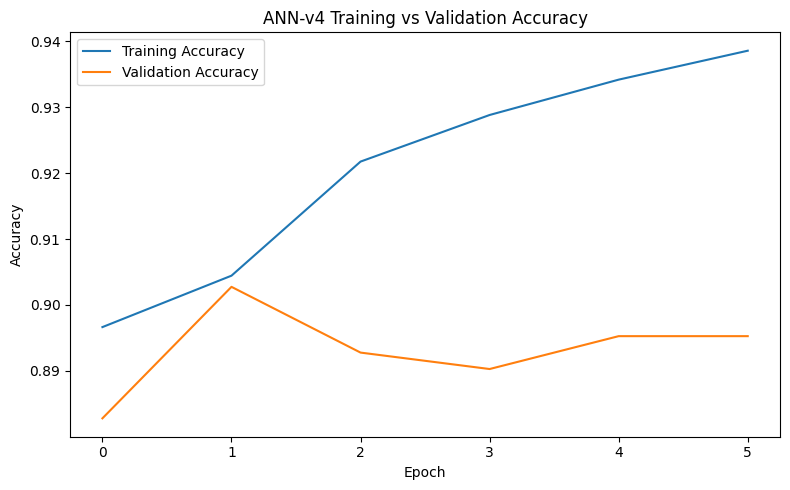

In [46]:
plt.figure(figsize=(8, 5))

plt.plot(
    history_v4.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history_v4.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("ANN-v4 Training vs Validation Accuracy")

plt.legend()
plt.tight_layout()
plt.show()

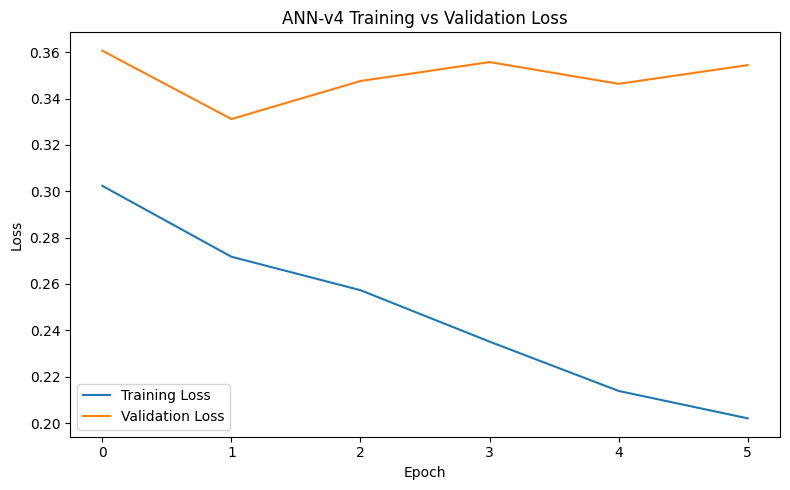

In [47]:
plt.figure(figsize=(8, 5))

plt.plot(
    history_v4.history["loss"],
    label="Training Loss"
)

plt.plot(
    history_v4.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("ANN-v4 Training vs Validation Loss")

plt.legend()
plt.tight_layout()
plt.show()

In [48]:
print("========== ANN-v4 RESULTS ==========")
print(f"Accuracy        : {ann_v4_accuracy:.4f}")
print(f"Macro Precision : {ann_v4_precision:.4f}")
print(f"Macro Recall    : {ann_v4_recall:.4f}")
print(f"Macro F1        : {ann_v4_f1:.4f}")

========== ANN-v4 RESULTS ==========
Accuracy        : 0.8578
Macro Precision : 0.8178
Macro Recall    : 0.8381
Macro F1        : 0.8256


In [49]:
## seeing this annv3 is good 
## Now cnn implenataion starts from here


In [50]:
# ============================================================
# ANN HYPERPARAMETER TUNING
# Fixed: Architecture, L2, BatchNorm, Optimizer, Batch Size
# Varied: Dropout Rates and Learning Rate
# ============================================================

ann_experiments = [
    {
        "name": "ANN-Exp1",
        "dropout": [0.20, 0.20, 0.20],
        "learning_rate": 1e-3
    },
    {
        "name": "ANN-Exp2",
        "dropout": [0.30, 0.30, 0.30],
        "learning_rate": 1e-3
    },
    {
        "name": "ANN-Exp3",
        "dropout": [0.40, 0.40, 0.40],
        "learning_rate": 1e-3
    },
    {
        "name": "ANN-Exp4",
        "dropout": [0.20, 0.20, 0.20],
        "learning_rate": 5e-4
    },
    {
        "name": "ANN-Exp5",
        "dropout": [0.30, 0.30, 0.30],
        "learning_rate": 5e-4
    },
    {
        "name": "ANN-Exp6",
        "dropout": [0.40, 0.40, 0.40],
        "learning_rate": 5e-4
    },
    {
        "name": "ANN-Exp7",
        "dropout": [0.35, 0.25, 0.15],
        "learning_rate": 3e-4
    }
]

print("Total experiments:", len(ann_experiments))

Total experiments: 7


In [51]:
def build_ann_experiment(dropout_rates, learning_rate):

    model = keras.Sequential(
        [
            keras.Input(
                shape=(X_train_scaled.shape[1],)
            ),

            layers.Dense(
                256,
                kernel_regularizer=regularizers.l2(5e-5)
            ),
            layers.BatchNormalization(),
            layers.Activation("relu"),
            layers.Dropout(dropout_rates[0]),

            layers.Dense(
                128,
                kernel_regularizer=regularizers.l2(5e-5)
            ),
            layers.BatchNormalization(),
            layers.Activation("relu"),
            layers.Dropout(dropout_rates[1]),

            layers.Dense(
                64,
                kernel_regularizer=regularizers.l2(5e-5)
            ),
            layers.BatchNormalization(),
            layers.Activation("relu"),
            layers.Dropout(dropout_rates[2]),

            layers.Dense(
                3,
                activation="softmax"
            )
        ],
        name="ANN_Hyperparameter_Model"
    )

    model.compile(
        optimizer=keras.optimizers.Adam(
            learning_rate=learning_rate
        ),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model

In [52]:
# ============================================================
# TRAIN AND EVALUATE ALL ANN CONFIGURATIONS
# ============================================================

ann_results = []

for exp in ann_experiments:

    print("\n" + "=" * 60)
    print(f"Running {exp['name']}")
    print(f"Dropout      : {exp['dropout']}")
    print(f"Learning Rate: {exp['learning_rate']}")
    print("=" * 60)

    model = build_ann_experiment(
        dropout_rates=exp["dropout"],
        learning_rate=exp["learning_rate"]
    )

    early_stopping = keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=8,
        restore_best_weights=True,
        verbose=0
    )

    reduce_lr = keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        min_lr=1e-6,
        verbose=0
    )

    history = model.fit(
        X_train_scaled,
        y_train_ann,
        validation_data=(
            X_val_scaled,
            y_val_ann
        ),
        epochs=50,
        batch_size=32,
        class_weight=ann_class_weights,
        callbacks=[
            early_stopping,
            reduce_lr
        ],
        verbose=0
    )

    test_prob = model.predict(
        X_test_scaled,
        verbose=0
    )

    y_pred = np.argmax(
        test_prob,
        axis=1
    )

    accuracy = accuracy_score(
        y_test_ann,
        y_pred
    )

    precision = precision_score(
        y_test_ann,
        y_pred,
        average="macro",
        zero_division=0
    )

    recall = recall_score(
        y_test_ann,
        y_pred,
        average="macro",
        zero_division=0
    )

    f1 = f1_score(
        y_test_ann,
        y_pred,
        average="macro",
        zero_division=0
    )

    ann_results.append(
        {
            "Model": exp["name"],
            "Dropout": str(exp["dropout"]),
            "Learning Rate": exp["learning_rate"],
            "Best Val Accuracy": max(
                history.history["val_accuracy"]
            ),
            "Best Val Loss": min(
                history.history["val_loss"]
            ),
            "Test Accuracy": accuracy,
            "Macro Precision": precision,
            "Macro Recall": recall,
            "Macro F1": f1
        }
    )

    print(f"Test Accuracy : {accuracy:.4f}")
    print(f"Macro Precision: {precision:.4f}")
    print(f"Macro Recall   : {recall:.4f}")
    print(f"Macro F1       : {f1:.4f}")


Running ANN-Exp1
Dropout      : [0.2, 0.2, 0.2]
Learning Rate: 0.001
Test Accuracy : 0.7958
Macro Precision: 0.7700
Macro Recall   : 0.7688
Macro F1       : 0.7637

Running ANN-Exp2
Dropout      : [0.3, 0.3, 0.3]
Learning Rate: 0.001
Test Accuracy : 0.8611
Macro Precision: 0.8307
Macro Recall   : 0.8478
Macro F1       : 0.8378

Running ANN-Exp3
Dropout      : [0.4, 0.4, 0.4]
Learning Rate: 0.001
Test Accuracy : 0.8154
Macro Precision: 0.7780
Macro Recall   : 0.8042
Macro F1       : 0.7853

Running ANN-Exp4
Dropout      : [0.2, 0.2, 0.2]
Learning Rate: 0.0005
Test Accuracy : 0.8203
Macro Precision: 0.7773
Macro Recall   : 0.7737
Macro F1       : 0.7745

Running ANN-Exp5
Dropout      : [0.3, 0.3, 0.3]
Learning Rate: 0.0005
Test Accuracy : 0.7810
Macro Precision: 0.7408
Macro Recall   : 0.7626
Macro F1       : 0.7448

Running ANN-Exp6
Dropout      : [0.4, 0.4, 0.4]
Learning Rate: 0.0005
Test Accuracy : 0.8431
Macro Precision: 0.8047
Macro Recall   : 0.8187
Macro F1       : 0.8105

Runnin

In [53]:
# ============================================================
# ANN EXPERIMENT COMPARISON
# ============================================================

ann_results_df = pd.DataFrame(
    ann_results
)

ann_results_df = ann_results_df.sort_values(
    by="Macro F1",
    ascending=False
).reset_index(drop=True)

ann_results_df

,Model,Dropout,Learning Rate,Best Val Accuracy,Best Val Loss,Test Accuracy,Macro Precision,Macro Recall,Macro F1
0,ANN-Exp2,"[0.3, 0.3, 0.3]",0.0010,0.892768,0.391995,0.861111,0.830706,0.847808,0.837767
1,ANN-Exp6,"[0.4, 0.4, 0.4]",0.0005,0.902743,0.443820,0.843137,0.804733,0.818734,0.810534
2,ANN-Exp7,"[0.35, 0.25, 0.15]",0.0003,0.912718,0.415166,0.826797,0.791115,0.816453,0.799869
3,ANN-Exp3,"[0.4, 0.4, 0.4]",0.0010,0.900249,0.410716,0.815359,0.777958,0.804181,0.785334
4,ANN-Exp4,"[0.2, 0.2, 0.2]",0.0005,0.882793,0.365631,0.820261,0.777274,0.773676,0.774523
5,ANN-Exp1,"[0.2, 0.2, 0.2]",0.0010,0.900249,0.426582,0.795752,0.770022,0.768805,0.763717
6,ANN-Exp5,"[0.3, 0.3, 0.3]",0.0005,0.907731,0.450205,0.781046,0.740777,0.762559,0.744834


In [54]:
best_ann = ann_results_df.iloc[0]

print("=" * 50)
print("BEST ANN CONFIGURATION")
print("=" * 50)

print(f"Model           : {best_ann['Model']}")
print(f"Dropout         : {best_ann['Dropout']}")
print(f"Learning Rate   : {best_ann['Learning Rate']}")
print(f"Test Accuracy   : {best_ann['Test Accuracy']:.4f}")
print(f"Macro Precision : {best_ann['Macro Precision']:.4f}")
print(f"Macro Recall    : {best_ann['Macro Recall']:.4f}")
print(f"Macro F1        : {best_ann['Macro F1']:.4f}")

BEST ANN CONFIGURATION
Model           : ANN-Exp2
Dropout         : [0.3, 0.3, 0.3]
Learning Rate   : 0.001
Test Accuracy   : 0.8611
Macro Precision : 0.8307
Macro Recall    : 0.8478
Macro F1        : 0.8378


In [55]:
X_train_cnn = X_train_final[..., np.newaxis]
X_val_cnn = X_val[..., np.newaxis]
X_test_cnn = X_test_images[..., np.newaxis]

y_train_cnn = y_train_final - 1
y_val_cnn = y_val - 1
y_test_cnn = y_test - 1

print("Training:", X_train_cnn.shape)
print("Validation:", X_val_cnn.shape)
print("Test:", X_test_cnn.shape)

Training: (2051, 128, 128, 1)
Validation: (401, 128, 128, 1)
Test: (612, 128, 128, 1)


In [56]:
from sklearn.utils.class_weight import compute_class_weight

classes_cnn = np.unique(y_train_cnn)

class_weights = compute_class_weight(
    class_weight="balanced",
    classes=classes_cnn,
    y=y_train_cnn
)

cnn_class_weights = {
    int(class_id): float(weight)
    for class_id, weight in zip(
        classes_cnn,
        class_weights
    )
}

print("CNN Class Weights")
print("-" * 30)

for class_id, weight in cnn_class_weights.items():
    print(f"Class {class_id}: {weight:.4f}")

CNN Class Weights
------------------------------
Class 0: 1.2341
Class 1: 0.6878
Class 2: 1.3592


In [57]:
# ============================================================
# MRI DATA AUGMENTATION
# ============================================================

cnn_augmentation = keras.Sequential(
    [
        layers.RandomRotation(
            factor=0.03,
            fill_mode="nearest"
        ),
        layers.RandomTranslation(
            height_factor=0.05,
            width_factor=0.05,
            fill_mode="nearest"
        ),
        layers.RandomZoom(
            height_factor=0.05,
            width_factor=0.05,
            fill_mode="nearest"
        )
    ],
    name="MRI_Augmentation"
)

In [58]:
# ============================================================
# CNN-V1 ARCHITECTURE
# ============================================================

cnn_model = keras.Sequential(
    [
        keras.Input(
            shape=(128, 128, 1)
        ),

        cnn_augmentation,

        # -------------------------
        # Convolution Block 1
        # -------------------------
        layers.Conv2D(
            32,
            kernel_size=3,
            padding="same",
            kernel_regularizer=regularizers.l2(1e-4)
        ),
        layers.BatchNormalization(),
        layers.Activation("relu"),

        layers.Conv2D(
            32,
            kernel_size=3,
            padding="same",
            kernel_regularizer=regularizers.l2(1e-4)
        ),
        layers.BatchNormalization(),
        layers.Activation("relu"),

        layers.MaxPooling2D(
            pool_size=2
        ),

        layers.Dropout(0.20),

        # -------------------------
        # Convolution Block 2
        # -------------------------
        layers.Conv2D(
            64,
            kernel_size=3,
            padding="same",
            kernel_regularizer=regularizers.l2(1e-4)
        ),
        layers.BatchNormalization(),
        layers.Activation("relu"),

        layers.Conv2D(
            64,
            kernel_size=3,
            padding="same",
            kernel_regularizer=regularizers.l2(1e-4)
        ),
        layers.BatchNormalization(),
        layers.Activation("relu"),

        layers.MaxPooling2D(
            pool_size=2
        ),

        layers.Dropout(0.25),

        # -------------------------
        # Convolution Block 3
        # -------------------------
        layers.Conv2D(
            128,
            kernel_size=3,
            padding="same",
            kernel_regularizer=regularizers.l2(1e-4)
        ),
        layers.BatchNormalization(),
        layers.Activation("relu"),

        layers.Conv2D(
            128,
            kernel_size=3,
            padding="same",
            kernel_regularizer=regularizers.l2(1e-4)
        ),
        layers.BatchNormalization(),
        layers.Activation("relu"),

        layers.MaxPooling2D(
            pool_size=2
        ),

        layers.Dropout(0.30),

        # -------------------------
        # Feature Aggregation
        # -------------------------
        layers.GlobalAveragePooling2D(),

        layers.Dense(
            128,
            kernel_regularizer=regularizers.l2(1e-4)
        ),
        layers.BatchNormalization(),
        layers.Activation("relu"),

        layers.Dropout(0.40),

        # -------------------------
        # Output
        # -------------------------
        layers.Dense(
            3,
            activation="softmax"
        )
    ],
    name="Brain_Tumor_CNN"
)

cnn_model.summary()

Model: "Brain_Tumor_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ MRI_Augmentation (Sequential)   │ (None, 128, 128, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_29          │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_30 (Activation)      │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 128, 128, 32)   │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_30          │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_31 (Activation)      │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_30 (Dropout)            │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_31          │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_32 (Activation)      │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 64, 64, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_32          │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_33 (Activation)      │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_31 (Dropout)            │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_33          │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_34 (Activation)      │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 32, 32, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_34          │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │             

 Total params: 305,635 (1.17 MB)

 Trainable params: 304,483 (1.16 MB)

 Non-trainable params: 1,152 (4.50 KB)

In [59]:
cnn_model.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=3e-4
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [60]:
# ============================================================
# CNN TRAINING CALLBACKS
# ============================================================

early_stopping_cnn = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=7,
    restore_best_weights=True,
    verbose=1
)

reduce_lr_cnn = keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=3,
    min_lr=1e-6,
    verbose=1
)

checkpoint_cnn = keras.callbacks.ModelCheckpoint(
    filepath=str(
        RESULTS_ROOT / "best_cnn_model.keras"
    ),
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

In [61]:
# ============================================================
# CNN TRAINING
# ============================================================

history_cnn = cnn_model.fit(
    X_train_cnn,
    y_train_cnn,
    validation_data=(
        X_val_cnn,
        y_val_cnn
    ),
    epochs=50,
    batch_size=32,
    class_weight=cnn_class_weights,
    callbacks=[
        early_stopping_cnn,
        reduce_lr_cnn,
        checkpoint_cnn
    ],
    verbose=1
)

Epoch 1/50
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 702ms/step - accuracy: 0.5888 - loss: 1.0049
Epoch 1: val_loss improved from inf to 1.23577, saving model to ../results/best_cnn_model.keras
65/65 ━━━━━━━━━━━━━━━━━━━━ 52s 753ms/step - accuracy: 0.5893 - loss: 1.0035 - val_accuracy: 0.3591 - val_loss: 1.2358 - learning_rate: 3.0000e-04
Epoch 2/50
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.6640 - loss: 0.7980
Epoch 2: val_loss did not improve from 1.23577
65/65 ━━━━━━━━━━━━━━━━━━━━ 91s 1s/step - accuracy: 0.6643 - loss: 0.7976 - val_accuracy: 0.3591 - val_loss: 1.3001 - learning_rate: 3.0000e-04
Epoch 3/50
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.6935 - loss: 0.7425
Epoch 3: val_loss improved from 1.23577 to 1.03585, saving model to ../results/best_cnn_model.keras
65/65 ━━━━━━━━━━━━━━━━━━━━ 84s 1s/step - accuracy: 0.6936 - loss: 0.7421 - val_accuracy: 0.3716 - val_loss: 1.0358 - learning_rate: 3.0000e-04
Epoch 4/50
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.7148 - los

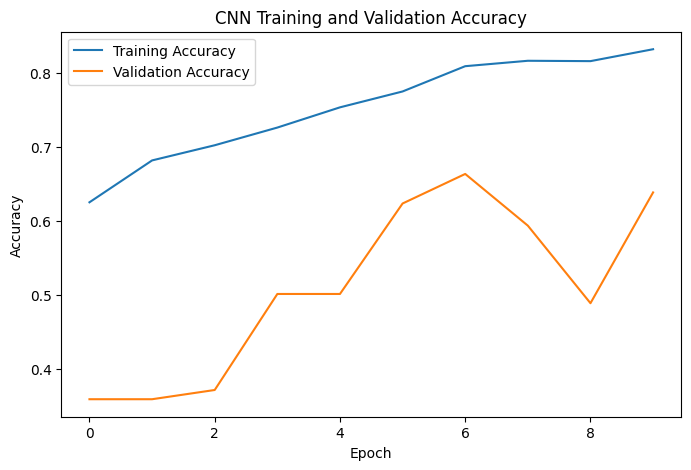

In [62]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    history_cnn.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history_cnn.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("CNN Training and Validation Accuracy")
plt.legend()
plt.show()

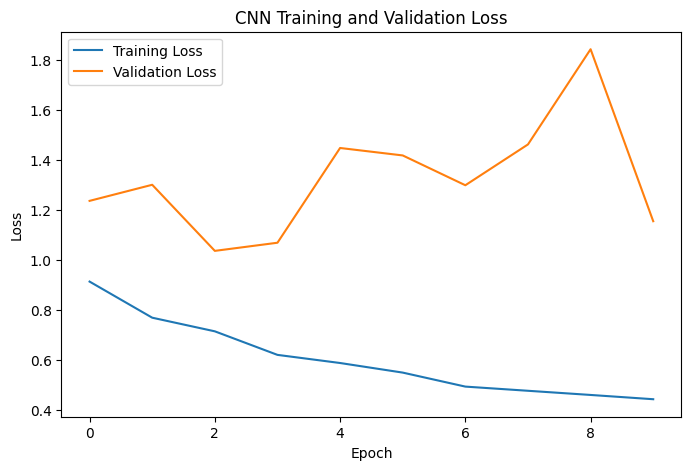

In [63]:
plt.figure(figsize=(8, 5))

plt.plot(
    history_cnn.history["loss"],
    label="Training Loss"
)

plt.plot(
    history_cnn.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("CNN Training and Validation Loss")
plt.legend()
plt.show()

In [64]:
# ============================================================
# CNN TEST EVALUATION
# ============================================================

best_cnn = keras.models.load_model(
    RESULTS_ROOT / "best_cnn_model.keras"
)

test_prob_cnn = best_cnn.predict(
    X_test_cnn,
    verbose=0
)

y_pred_cnn = np.argmax(
    test_prob_cnn,
    axis=1
)

In [65]:
cnn_accuracy = accuracy_score(
    y_test_cnn,
    y_pred_cnn
)

cnn_precision = precision_score(
    y_test_cnn,
    y_pred_cnn,
    average="macro",
    zero_division=0
)

cnn_recall = recall_score(
    y_test_cnn,
    y_pred_cnn,
    average="macro",
    zero_division=0
)

cnn_f1 = f1_score(
    y_test_cnn,
    y_pred_cnn,
    average="macro",
    zero_division=0
)

print("========== CNN RESULTS ==========")

print(f"Accuracy        : {cnn_accuracy:.4f}")
print(f"Macro Precision : {cnn_precision:.4f}")
print(f"Macro Recall    : {cnn_recall:.4f}")
print(f"Macro F1        : {cnn_f1:.4f}")

========== CNN RESULTS ==========
Accuracy        : 0.4020
Macro Precision : 0.2741
Macro Recall    : 0.3273
Macro F1        : 0.2907


In [66]:
print(
    classification_report(
        y_test_cnn,
        y_pred_cnn,
        digits=4
    )
)

              precision    recall  f1-score   support

           0     0.0000    0.0000    0.0000        98
           1     0.4571    0.3889    0.4203       288
           2     0.3651    0.5929    0.4519       226

    accuracy                         0.4020       612
   macro avg     0.2741    0.3273    0.2907       612
weighted avg     0.3500    0.4020    0.3647       612



/Users/harshitabhardwaj/Desktop/Brain_Tumor_Detection/.venv/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/Users/harshitabhardwaj/Desktop/Brain_Tumor_Detection/.venv/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/Users/harshitabhardwaj/Desktop/Brain_Tumor_Detection/.venv/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to c

In [67]:
print("Train:", np.unique(y_train_cnn, return_counts=True))
print("Val  :", np.unique(y_val_cnn, return_counts=True))
print("Test :", np.unique(y_test_cnn, return_counts=True))

Train: (array([0, 1, 2]), array([554, 994, 503]))
Val  : (array([0, 1, 2]), array([ 56, 144, 201]))
Test : (array([0, 1, 2]), array([ 98, 288, 226]))


In [68]:
print(cnn_class_weights)

{0: 1.2340553549939832, 1: 0.687793427230047, 2: 1.3591782637508283}


In [69]:
print(
    "Predictions:",
    np.unique(y_pred_cnn, return_counts=True)
)

Predictions: (array([1, 2]), array([245, 367]))


In [70]:
print("Training accuracy:")
print(history_cnn.history["accuracy"])

print("\nValidation accuracy:")
print(history_cnn.history["val_accuracy"])

print("\nTraining loss:")
print(history_cnn.history["loss"])

print("\nValidation loss:")
print(history_cnn.history["val_loss"])

Training accuracy:
[0.6250609755516052, 0.6816187500953674, 0.7020965218544006, 0.7259873151779175, 0.7532910704612732, 0.7747440338134766, 0.80887371301651, 0.8161872029304504, 0.8156996369361877, 0.8317893743515015]

Validation accuracy:
[0.3591022491455078, 0.3591022491455078, 0.37157106399536133, 0.5012468695640564, 0.5012468695640564, 0.6234413981437683, 0.6633416414260864, 0.5935162305831909, 0.4887780547142029, 0.6384040117263794]

Training loss:
[0.9130281805992126, 0.7687032222747803, 0.714178204536438, 0.6200547218322754, 0.5875427722930908, 0.5492070317268372, 0.4932195246219635, 0.4765204191207886, 0.45985132455825806, 0.4427647590637207]

Validation loss:
[1.2357734441757202, 1.3000779151916504, 1.0358490943908691, 1.0683740377426147, 1.4471749067306519, 1.417375922203064, 1.298190951347351, 1.4613988399505615, 1.8420003652572632, 1.1543768644332886]


In [71]:
print("Final learning rate:")

print(
    float(
        cnn_model.optimizer.learning_rate.numpy()
    )
)

Final learning rate:
7.500000356230885e-05


In [72]:
print("First 10 prediction probabilities:")

print(
    test_prob_cnn[:10]
)

First 10 prediction probabilities:
[[0.08129243 0.46513286 0.4535747 ]
 [0.08116513 0.4645285  0.45430636]
 [0.07579543 0.46276075 0.46144396]
 [0.07766963 0.45374072 0.46858975]
 [0.07826497 0.45985383 0.46188125]
 [0.07763629 0.46635863 0.45600513]
 [0.07818923 0.47257793 0.44923285]
 [0.09486935 0.4301573  0.47497326]
 [0.09086087 0.4303393  0.47879988]
 [0.07406791 0.44163173 0.4843003 ]]


In [73]:
print("Current model evaluation:")
cnn_current_prob = cnn_model.predict(
    X_test_cnn,
    verbose=0
)

cnn_current_pred = np.argmax(cnn_current_prob, axis=1)

print(
    np.unique(
        cnn_current_pred,
        return_counts=True
    )
)

print("\nCheckpoint model evaluation:")

best_cnn = keras.models.load_model(
    RESULTS_ROOT / "best_cnn_model.keras"
)

cnn_best_prob = best_cnn.predict(
    X_test_cnn,
    verbose=0
)

cnn_best_pred = np.argmax(cnn_best_prob, axis=1)

print(
    np.unique(
        cnn_best_pred,
        return_counts=True
    )
)

Current model evaluation:
(array([1, 2]), array([245, 367]))

Checkpoint model evaluation:
(array([1, 2]), array([245, 367]))


In [74]:
print("Current model evaluation:")
cnn_current_prob = cnn_model.predict(
    X_test_cnn,
    verbose=0
)

cnn_current_pred = np.argmax(cnn_current_prob, axis=1)

print(
    np.unique(
        cnn_current_pred,
        return_counts=True
    )
)

print("\nCheckpoint model evaluation:")

best_cnn = keras.models.load_model(
    RESULTS_ROOT / "best_cnn_model.keras"
)

cnn_best_prob = best_cnn.predict(
    X_test_cnn,
    verbose=0
)

cnn_best_pred = np.argmax(cnn_best_prob, axis=1)

print(
    np.unique(
        cnn_best_pred,
        return_counts=True
    )
)

Current model evaluation:
(array([1, 2]), array([245, 367]))

Checkpoint model evaluation:
(array([1, 2]), array([245, 367]))


In [75]:
cnn_v2 = keras.Sequential(
    [
        keras.Input(shape=(128, 128, 1)),

        cnn_augmentation,

        # Block 1
        layers.Conv2D(
            32, 3, padding="same"
        ),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.MaxPooling2D(2),
        layers.Dropout(0.15),

        # Block 2
        layers.Conv2D(
            64, 3, padding="same"
        ),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.Conv2D(
            64, 3, padding="same"
        ),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.MaxPooling2D(2),
        layers.Dropout(0.20),

        # Block 3
        layers.Conv2D(
            128, 3, padding="same"
        ),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.MaxPooling2D(2),
        layers.Dropout(0.25),

        # Feature aggregation
        layers.GlobalAveragePooling2D(),

        layers.Dense(128),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.Dropout(0.30),

        layers.Dense(
            3,
            activation="softmax"
        )
    ],
    name="Brain_Tumor_CNN_v2"
)

In [76]:
cnn_v2.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=1e-4
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [77]:
early_stopping_cnn_v2 = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=8,
    restore_best_weights=True,
    verbose=1
)

reduce_lr_cnn_v2 = keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=3,
    min_lr=1e-6,
    verbose=1
)

checkpoint_cnn_v2 = keras.callbacks.ModelCheckpoint(
    filepath=str(
        RESULTS_ROOT / "best_cnn_v2.keras"
    ),
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

In [78]:
history_cnn_v2 = cnn_v2.fit(
    X_train_cnn,
    y_train_cnn,
    validation_data=(
        X_val_cnn,
        y_val_cnn
    ),
    epochs=50,
    batch_size=32,
    class_weight=cnn_class_weights,
    callbacks=[
        early_stopping_cnn_v2,
        reduce_lr_cnn_v2,
        checkpoint_cnn_v2
    ],
    verbose=1
)


Epoch 1/50
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 591ms/step - accuracy: 0.5135 - loss: 0.9557
Epoch 1: val_loss improved from inf to 1.12424, saving model to ../results/best_cnn_v2.keras
65/65 ━━━━━━━━━━━━━━━━━━━━ 44s 627ms/step - accuracy: 0.5142 - loss: 0.9546 - val_accuracy: 0.1397 - val_loss: 1.1242 - learning_rate: 1.0000e-04
Epoch 2/50
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 733ms/step - accuracy: 0.6020 - loss: 0.7955
Epoch 2: val_loss did not improve from 1.12424
65/65 ━━━━━━━━━━━━━━━━━━━━ 50s 767ms/step - accuracy: 0.6021 - loss: 0.7953 - val_accuracy: 0.1372 - val_loss: 1.1513 - learning_rate: 1.0000e-04
Epoch 3/50
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 619ms/step - accuracy: 0.6407 - loss: 0.7447
Epoch 3: val_loss improved from 1.12424 to 1.10648, saving model to ../results/best_cnn_v2.keras
65/65 ━━━━━━━━━━━━━━━━━━━━ 42s 650ms/step - accuracy: 0.6408 - loss: 0.7447 - val_accuracy: 0.3591 - val_loss: 1.1065 - learning_rate: 1.0000e-04
Epoch 4/50
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 670ms/step - accuracy: 0.6

In [79]:
best_cnn_v2 = keras.models.load_model(
    RESULTS_ROOT / "best_cnn_v2.keras"
)

test_prob_cnn_v2 = best_cnn_v2.predict(
    X_test_cnn,
    verbose=0
)

y_pred_cnn_v2 = np.argmax(
    test_prob_cnn_v2,
    axis=1
)

print(
    np.unique(
        y_pred_cnn_v2,
        return_counts=True
    )
)

(array([0, 1, 2]), array([  7, 366, 239]))


In [80]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

print("CNN-v2 Classification Report:\n")

print(
    classification_report(
        y_test_cnn,
        y_pred_cnn_v2,
        target_names=[
            "Class 0",
            "Class 1",
            "Class 2"
        ],
        digits=4
    )
)

print("Accuracy:",
      accuracy_score(y_test_cnn, y_pred_cnn_v2))

print("Macro Precision:",
      precision_score(
          y_test_cnn,
          y_pred_cnn_v2,
          average="macro"
      ))

print("Macro Recall:",
      recall_score(
          y_test_cnn,
          y_pred_cnn_v2,
          average="macro"
      ))

print("Macro F1:",
      f1_score(
          y_test_cnn,
          y_pred_cnn_v2,
          average="macro"
      ))

print("\nConfusion Matrix:")
print(
    confusion_matrix(
        y_test_cnn,
        y_pred_cnn_v2
    )
)

CNN-v2 Classification Report:

              precision    recall  f1-score   support

     Class 0     0.2857    0.0204    0.0381        98
     Class 1     0.7432    0.9444    0.8318       288
     Class 2     0.8703    0.9204    0.8946       226

    accuracy                         0.7876       612
   macro avg     0.6331    0.6284    0.5882       612
weighted avg     0.7169    0.7876    0.7279       612

Accuracy: 0.7875816993464052
Macro Precision: 0.6330588572168928
Macro Recall: 0.6284021966702119
Macro F1: 0.5881743917849275

Confusion Matrix:
[[  2  76  20]
 [  5 272  11]
 [  0  18 208]]


In [81]:
print("Original labels:", np.unique(labels))

for original_label, class_name in zip(
    [1, 2, 3],
    ["Glioma", "Meningioma", "Pituitary"]
):
    print(original_label, "->", class_name)

Original labels: [1 2 3]
1 -> Glioma
2 -> Meningioma
3 -> Pituitary


In [82]:
print("CNN labels:")
print("0 -> original label 1")
print("1 -> original label 2")
print("2 -> original label 3")

CNN labels:
0 -> original label 1
1 -> original label 2
2 -> original label 3


In [83]:
cnn_v3 = keras.Sequential(
    [
        keras.Input(shape=(128, 128, 1)),

        cnn_augmentation,

        # Block 1
        layers.Conv2D(
            32,
            kernel_size=3,
            padding="same"
        ),
        layers.BatchNormalization(),
        layers.Activation("relu"),

        layers.Conv2D(
            32,
            kernel_size=3,
            padding="same"
        ),
        layers.BatchNormalization(),
        layers.Activation("relu"),

        layers.MaxPooling2D(pool_size=2),
        layers.Dropout(0.15),

        # Block 2
        layers.Conv2D(
            64,
            kernel_size=3,
            padding="same"
        ),
        layers.BatchNormalization(),
        layers.Activation("relu"),

        layers.Conv2D(
            64,
            kernel_size=3,
            padding="same"
        ),
        layers.BatchNormalization(),
        layers.Activation("relu"),

        layers.MaxPooling2D(pool_size=2),
        layers.Dropout(0.20),

        # Block 3
        layers.Conv2D(
            128,
            kernel_size=3,
            padding="same"
        ),
        layers.BatchNormalization(),
        layers.Activation("relu"),

        layers.Conv2D(
            128,
            kernel_size=3,
            padding="same"
        ),
        layers.BatchNormalization(),
        layers.Activation("relu"),

        layers.MaxPooling2D(pool_size=2),
        layers.Dropout(0.25),

        # Block 4
        layers.Conv2D(
            256,
            kernel_size=3,
            padding="same"
        ),
        layers.BatchNormalization(),
        layers.Activation("relu"),

        layers.MaxPooling2D(pool_size=2),
        layers.Dropout(0.25),

        # Feature aggregation
        layers.GlobalAveragePooling2D(),

        layers.Dense(128),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.Dropout(0.30),

        # Output
        layers.Dense(
            3,
            activation="softmax"
        )
    ],
    name="Brain_Tumor_CNN_v3"
)

In [84]:
cnn_v3.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=1e-4
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [85]:
early_stopping_cnn_v3 = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=8,
    restore_best_weights=True,
    verbose=1
)

reduce_lr_cnn_v3 = keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=3,
    min_lr=1e-6,
    verbose=1
)

checkpoint_cnn_v3 = keras.callbacks.ModelCheckpoint(
    filepath=str(
        RESULTS_ROOT / "best_cnn_v3.keras"
    ),
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

In [86]:
history_cnn_v3 = cnn_v3.fit(
    X_train_cnn,
    y_train_cnn,
    validation_data=(
        X_val_cnn,
        y_val_cnn
    ),
    epochs=50,
    batch_size=32,
    class_weight=cnn_class_weights,
    callbacks=[
        early_stopping_cnn_v3,
        reduce_lr_cnn_v3,
        checkpoint_cnn_v3
    ],
    verbose=1
)

Epoch 1/50
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.5146 - loss: 1.0199
Epoch 1: val_loss improved from inf to 1.06751, saving model to ../results/best_cnn_v3.keras
65/65 ━━━━━━━━━━━━━━━━━━━━ 106s 2s/step - accuracy: 0.5155 - loss: 1.0186 - val_accuracy: 0.3591 - val_loss: 1.0675 - learning_rate: 1.0000e-04
Epoch 2/50
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.6398 - loss: 0.7852
Epoch 2: val_loss improved from 1.06751 to 1.05173, saving model to ../results/best_cnn_v3.keras
65/65 ━━━━━━━━━━━━━━━━━━━━ 100s 2s/step - accuracy: 0.6400 - loss: 0.7849 - val_accuracy: 0.3591 - val_loss: 1.0517 - learning_rate: 1.0000e-04
Epoch 3/50
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.6734 - loss: 0.7287
Epoch 3: val_loss did not improve from 1.05173
65/65 ━━━━━━━━━━━━━━━━━━━━ 98s 2s/step - accuracy: 0.6735 - loss: 0.7284 - val_accuracy: 0.6185 - val_loss: 1.0715 - learning_rate: 1.0000e-04
Epoch 4/50
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.7123 - loss: 0.6458


In [87]:
best_cnn_v3 = keras.models.load_model(
    RESULTS_ROOT / "best_cnn_v3.keras"
)

test_prob_cnn_v3 = best_cnn_v3.predict(
    X_test_cnn,
    verbose=0
)

y_pred_cnn_v3 = np.argmax(
    test_prob_cnn_v3,
    axis=1
)

print(
    "Prediction distribution:",
    np.unique(
        y_pred_cnn_v3,
        return_counts=True
    )
)

Prediction distribution: (array([1, 2]), array([349, 263]))


In [88]:
print("Train pixel statistics:")
print("Min:", X_train_cnn.min())
print("Max:", X_train_cnn.max())
print("Mean:", X_train_cnn.mean())
print("Std:", X_train_cnn.std())

print("\nValidation pixel statistics:")
print("Min:", X_val_cnn.min())
print("Max:", X_val_cnn.max())
print("Mean:", X_val_cnn.mean())
print("Std:", X_val_cnn.std())

print("\nTest pixel statistics:")
print("Min:", X_test_cnn.min())
print("Max:", X_test_cnn.max())
print("Mean:", X_test_cnn.mean())
print("Std:", X_test_cnn.std())

Train pixel statistics:
Min: 0.0
Max: 1.0
Mean: 0.18868329
Std: 0.19725342

Validation pixel statistics:
Min: 0.0
Max: 1.0
Mean: 0.19971013
Std: 0.19670263

Test pixel statistics:
Min: 0.0
Max: 1.0
Mean: 0.19466703
Std: 0.19543687


In [89]:
print("Individual image statistics:")

for i in range(5):
    img = X_train_cnn[i]

    print(
        f"Image {i}: "
        f"min={img.min():.4f}, "
        f"max={img.max():.4f}, "
        f"mean={img.mean():.4f}, "
        f"std={img.std():.4f}"
    )

Individual image statistics:
Image 0: min=0.0000, max=1.0000, mean=0.2571, std=0.1961
Image 1: min=0.0000, max=1.0000, mean=0.2553, std=0.1936
Image 2: min=0.0000, max=1.0000, mean=0.2609, std=0.1948
Image 3: min=0.0000, max=1.0000, mean=0.2214, std=0.1638
Image 4: min=0.0000, max=1.0000, mean=0.2284, std=0.1677


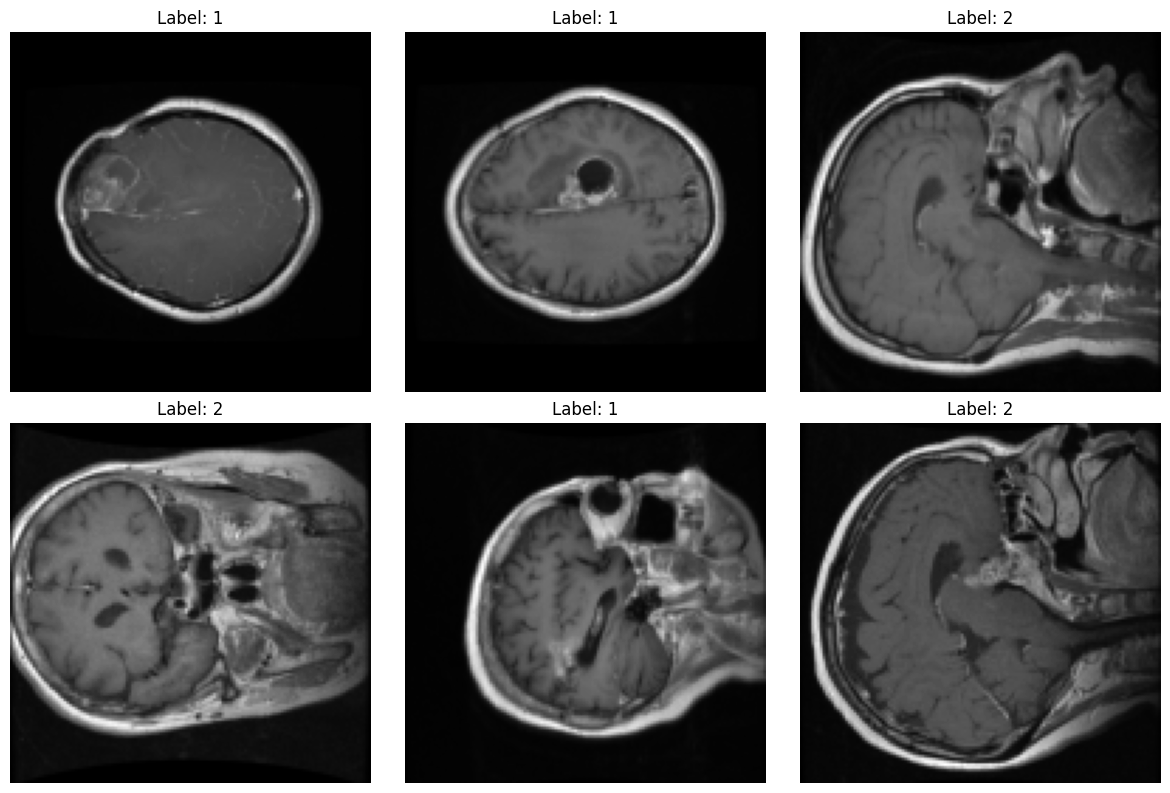

In [90]:
import matplotlib.pyplot as plt
import numpy as np

indices = np.random.choice(
    len(X_train_cnn),
    size=6,
    replace=False
)

plt.figure(figsize=(12, 8))

for i, idx in enumerate(indices):
    plt.subplot(2, 3, i + 1)
    plt.imshow(
        X_train_cnn[idx].squeeze(),
        cmap="gray"
    )
    plt.title(f"Label: {y_train_cnn[idx]}")
    plt.axis("off")

plt.tight_layout()
plt.show()

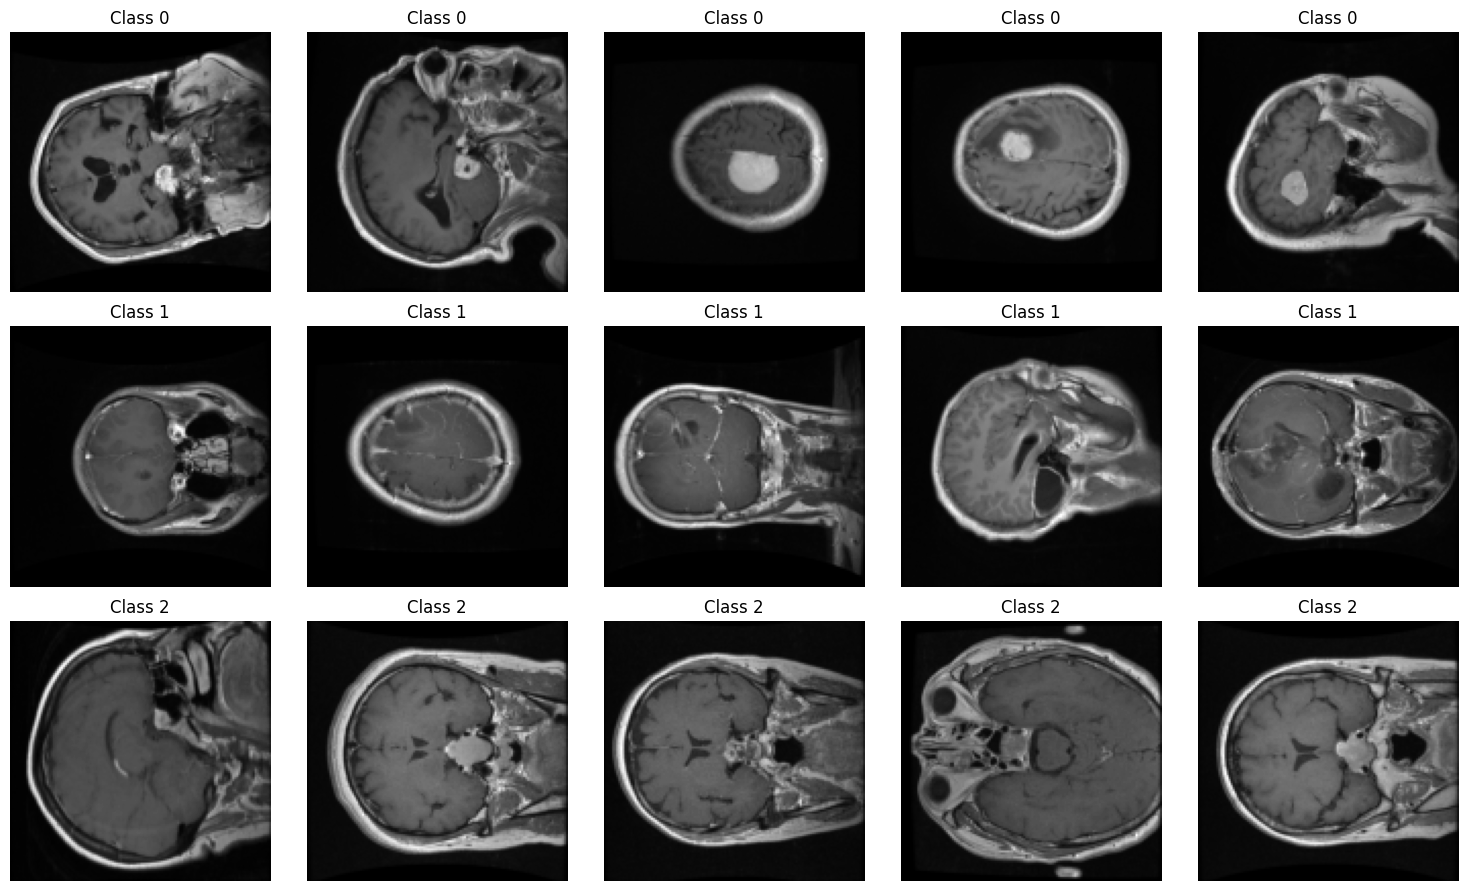

In [91]:
import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(3, 5, figsize=(15, 9))

for class_id in [0, 1, 2]:

    class_indices = np.where(
        y_train_cnn == class_id
    )[0]

    selected = np.random.choice(
        class_indices,
        size=5,
        replace=False
    )

    for j, idx in enumerate(selected):

        axes[class_id, j].imshow(
            X_train_cnn[idx].squeeze(),
            cmap="gray"
        )

        axes[class_id, j].set_title(
            f"Class {class_id}"
        )

        axes[class_id, j].axis("off")

plt.tight_layout()
plt.show()

In [92]:
# Transfer Learning CNN
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Convert grayscale MRI to 3-channel RGB-like format
X_train_tl = np.repeat(
    X_train_cnn,
    3,
    axis=-1
)

X_val_tl = np.repeat(
    X_val_cnn,
    3,
    axis=-1
)

X_test_tl = np.repeat(
    X_test_cnn,
    3,
    axis=-1
)

print("Train:", X_train_tl.shape)
print("Validation:", X_val_tl.shape)
print("Test:", X_test_tl.shape)

Train: (2051, 128, 128, 3)
Validation: (401, 128, 128, 3)
Test: (612, 128, 128, 3)


In [93]:
tl_augmentation = keras.Sequential(
    [
        layers.RandomRotation(
            factor=0.03,
            fill_mode="nearest"
        ),
        layers.RandomTranslation(
            height_factor=0.04,
            width_factor=0.04,
            fill_mode="nearest"
        ),
        layers.RandomZoom(
            height_factor=0.05,
            width_factor=0.05,
            fill_mode="nearest"
        )
    ],
    name="MRI_TL_Augmentation"
)

In [94]:
base_model = keras.applications.EfficientNetB0(
    include_top=False,
    weights="imagenet",
    input_shape=(128, 128, 3)
)

base_model.trainable = False

print("Total backbone layers:", len(base_model.layers))

Total backbone layers: 238


In [95]:
inputs = keras.Input(
    shape=(128, 128, 3)
)

x = tl_augmentation(inputs)

x = base_model(
    x,
    training=False
)

x = layers.GlobalAveragePooling2D()(x)

x = layers.Dense(128)(x)
x = layers.BatchNormalization()(x)
x = layers.Activation("relu")(x)
x = layers.Dropout(0.30)(x)

outputs = layers.Dense(
    3,
    activation="softmax"
)(x)

cnn_tl = keras.Model(
    inputs,
    outputs,
    name="Brain_Tumor_EfficientNetB0"
)

cnn_tl.summary()

Model: "Brain_Tumor_EfficientNetB0"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_16 (InputLayer)     │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ MRI_TL_Augmentation             │ (None, 128, 128, 3)    │             0 │
│ (Sequential)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 4, 4, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_3      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_46 (Dense)                │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_49          │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_50 (Activation)      │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_43 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_47 (Dense)                │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,214,438 (16.08 MB)

 Trainable params: 164,611 (643.01 KB)

 Non-trainable params: 4,049,827 (15.45 MB)

In [96]:
cnn_tl.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=1e-4
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [97]:
early_stopping_tl = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=7,
    restore_best_weights=True,
    verbose=1
)

reduce_lr_tl = keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=3,
    min_lr=1e-6,
    verbose=1
)

checkpoint_tl = keras.callbacks.ModelCheckpoint(
    filepath=str(
        RESULTS_ROOT / "best_cnn_transfer_learning.keras"
    ),
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

In [98]:
history_tl = cnn_tl.fit(
    X_train_tl,
    y_train_cnn,

    validation_data=(
        X_val_tl,
        y_val_cnn
    ),

    epochs=25,
    batch_size=32,

    class_weight=cnn_class_weights,

    callbacks=[
        early_stopping_tl,
        reduce_lr_tl,
        checkpoint_tl
    ],

    verbose=1
)

Epoch 1/25
64/65 ━━━━━━━━━━━━━━━━━━━━ 0s 274ms/step - accuracy: 0.3153 - loss: 1.2289
Epoch 1: val_loss improved from inf to 1.08980, saving model to ../results/best_cnn_transfer_learning.keras
65/65 ━━━━━━━━━━━━━━━━━━━━ 34s 378ms/step - accuracy: 0.3157 - loss: 1.2281 - val_accuracy: 0.5012 - val_loss: 1.0898 - learning_rate: 1.0000e-04
Epoch 2/25
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 266ms/step - accuracy: 0.3693 - loss: 1.1722
Epoch 2: val_loss did not improve from 1.08980
65/65 ━━━━━━━━━━━━━━━━━━━━ 21s 325ms/step - accuracy: 0.3693 - loss: 1.1721 - val_accuracy: 0.1397 - val_loss: 1.1039 - learning_rate: 1.0000e-04
Epoch 3/25
64/65 ━━━━━━━━━━━━━━━━━━━━ 0s 207ms/step - accuracy: 0.3643 - loss: 1.1607
Epoch 3: val_loss did not improve from 1.08980
65/65 ━━━━━━━━━━━━━━━━━━━━ 16s 236ms/step - accuracy: 0.3646 - loss: 1.1607 - val_accuracy: 0.1397 - val_loss: 1.1318 - learning_rate: 1.0000e-04
Epoch 4/25
64/65 ━━━━━━━━━━━━━━━━━━━━ 0s 168ms/step - accuracy: 0.3529 - loss: 1.1824
Epoch 4: ReduceL

In [99]:
best_cnn_tl = keras.models.load_model(
    RESULTS_ROOT / "best_cnn_transfer_learning.keras"
)

test_prob_tl = best_cnn_tl.predict(
    X_test_tl,
    verbose=0
)

y_pred_tl = np.argmax(
    test_prob_tl,
    axis=1
)

print(
    "Prediction distribution:",
    np.unique(
        y_pred_tl,
        return_counts=True
    )
)

Prediction distribution: (array([2]), array([612]))


In [100]:
## Lenet
import os 
import numpy as np
import pandas as pd
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

SEED = 42

np.random.seed(SEED)
tf.random.set_seed(SEED)

IMG_SIZE_CNN = 224
NUM_CLASSES = 3
BATCH_SIZE = 32

In [101]:
def prepare_cnn_images(
    X,
    target_size=(224, 224)
):
    
    X = np.asarray(X, dtype=np.float32)

    # Add channel dimension
    if X.ndim == 3:
        X = X[..., np.newaxis]

    # Convert grayscale → 3 channels
    X = np.repeat(X, 3, axis=-1)

    # Resize
    X = tf.image.resize(
        X,
        target_size,
        method="bilinear"
    )

    return X.numpy().astype(np.float32)

In [102]:
X_train_224 = prepare_cnn_images(
    X_train_cnn
)

X_val_224 = prepare_cnn_images(
    X_val_cnn
)

X_test_224 = prepare_cnn_images(
    X_test_cnn
)

print("Train:", X_train_224.shape)
print("Validation:", X_val_224.shape)
print("Test:", X_test_224.shape)

Train: (2051, 224, 224, 3)
Validation: (401, 224, 224, 3)
Test: (612, 224, 224, 3)


In [103]:
cnn_results = []


def evaluate_cnn_model(
    model,
    model_name,
    X_test,
    y_test
):
    
    probabilities = model.predict(
        X_test,
        batch_size=BATCH_SIZE,
        verbose=0
    )

    predictions = np.argmax(
        probabilities,
        axis=1
    )

    accuracy = accuracy_score(
        y_test,
        predictions
    )

    precision = precision_score(
        y_test,
        predictions,
        average="macro",
        zero_division=0
    )

    recall = recall_score(
        y_test,
        predictions,
        average="macro",
        zero_division=0
    )

    f1 = f1_score(
        y_test,
        predictions,
        average="macro",
        zero_division=0
    )

    print("\n" + "=" * 70)
    print(f"{model_name} - CLASSIFICATION REPORT")
    print("=" * 70)

    print(
        classification_report(
            y_test,
            predictions,
            digits=4,
            zero_division=0
        )
    )

    print("Confusion Matrix:")
    print(
        confusion_matrix(
            y_test,
            predictions
        )
    )

    print("\nPrediction Distribution:")
    print(
        np.unique(
            predictions,
            return_counts=True
        )
    )

    print("\nMetrics:")
    print(f"Accuracy       : {accuracy:.4f}")
    print(f"Macro Precision: {precision:.4f}")
    print(f"Macro Recall   : {recall:.4f}")
    print(f"Macro F1       : {f1:.4f}")

    cnn_results.append(
        {
            "Model": model_name,
            "Accuracy": accuracy,
            "Macro Precision": precision,
            "Macro Recall": recall,
            "Macro F1": f1
        }
    )

    return predictions, probabilities

In [104]:
def create_callbacks(model_name):

    model_path = (
        RESULTS_ROOT /
        f"best_{model_name.lower().replace(' ', '_')}.keras"
    )

    return [

        keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=7,
            restore_best_weights=True,
            verbose=1
        ),

        keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.5,
            patience=3,
            min_lr=1e-7,
            verbose=1
        ),

        keras.callbacks.ModelCheckpoint(
            filepath=str(model_path),
            monitor="val_loss",
            save_best_only=True,
            verbose=1
        )
    ]

In [105]:
def build_lenet():

    inputs = keras.Input(
        shape=(224, 224, 3)
    )

    x = layers.Conv2D(
        6,
        kernel_size=5,
        activation="tanh",
        padding="same"
    )(inputs)

    x = layers.AveragePooling2D(
        pool_size=2
    )(x)

    x = layers.Conv2D(
        16,
        kernel_size=5,
        activation="tanh"
    )(x)

    x = layers.AveragePooling2D(
        pool_size=2
    )(x)

    x = layers.Conv2D(
        120,
        kernel_size=5,
        activation="tanh"
    )(x)

    x = layers.Flatten()(x)

    x = layers.Dense(
        84,
        activation="tanh"
    )(x)

    x = layers.Dropout(0.30)(x)

    outputs = layers.Dense(
        NUM_CLASSES,
        activation="softmax"
    )(x)

    return keras.Model(
        inputs,
        outputs,
        name="LeNet"
    )

In [106]:
lenet = build_lenet()

lenet.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=1e-3
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

lenet.summary()

Model: "LeNet"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_18 (InputLayer)     │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_17 (Conv2D)              │ (None, 224, 224, 6)    │           456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d               │ (None, 112, 112, 6)    │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_18 (Conv2D)              │ (None, 108, 108, 16)   │         2,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_1             │ (None, 54, 54, 16)     │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_19 (Conv2D)              │ (None, 50, 50, 120)    │        48,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 300000)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_48 (Dense)                │ (None, 84)             │    25,200,084 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_44 (Dropout)            │ (None, 84)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_49 (Dense)                │ (None, 3)              │           255 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 25,251,331 (96.33 MB)

 Trainable params: 25,251,331 (96.33 MB)

 Non-trainable params: 0 (0.00 B)

In [107]:
history_lenet = lenet.fit(
    X_train_224,
    y_train_cnn,

    validation_data=(
        X_val_224,
        y_val_cnn
    ),

    epochs=30,
    batch_size=BATCH_SIZE,

    class_weight=cnn_class_weights,

    callbacks=create_callbacks(
        "LeNet"
    ),

    verbose=1
)

Epoch 1/30
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 392ms/step - accuracy: 0.4312 - loss: 1.4274
Epoch 1: val_loss improved from inf to 0.86883, saving model to ../results/best_lenet.keras
65/65 ━━━━━━━━━━━━━━━━━━━━ 30s 439ms/step - accuracy: 0.4316 - loss: 1.4237 - val_accuracy: 0.4963 - val_loss: 0.8688 - learning_rate: 0.0010
Epoch 2/30
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 371ms/step - accuracy: 0.4830 - loss: 1.0424
Epoch 2: val_loss improved from 0.86883 to 0.79616, saving model to ../results/best_lenet.keras
65/65 ━━━━━━━━━━━━━━━━━━━━ 26s 393ms/step - accuracy: 0.4830 - loss: 1.0424 - val_accuracy: 0.5985 - val_loss: 0.7962 - learning_rate: 0.0010
Epoch 3/30
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 358ms/step - accuracy: 0.5025 - loss: 0.9928
Epoch 3: val_loss improved from 0.79616 to 0.78225, saving model to ../results/best_lenet.keras
65/65 ━━━━━━━━━━━━━━━━━━━━ 25s 382ms/step - accuracy: 0.5025 - loss: 0.9928 - val_accuracy: 0.6608 - val_loss: 0.7823 - learning_rate: 0.0010
Epoch 4/30
65/65 ━━━━━━━━━━━━━━━

In [108]:
lenet_pred, lenet_prob = evaluate_cnn_model(
    lenet,
    "LeNet",
    X_test_224,
    y_test_cnn
)


LeNet - CLASSIFICATION REPORT
              precision    recall  f1-score   support

           0     0.2146    0.4490    0.2904        98
           1     0.6628    0.1979    0.3048       288
           2     0.6449    0.9159    0.7569       226

    accuracy                         0.5033       612
   macro avg     0.5074    0.5209    0.4507       612
weighted avg     0.5844    0.5033    0.4694       612

Confusion Matrix:
[[ 44  15  39]
 [156  57  75]
 [  5  14 207]]

Prediction Distribution:
(array([0, 1, 2]), array([205,  86, 321]))

Metrics:
Accuracy       : 0.5033
Macro Precision: 0.5074
Macro Recall   : 0.5209
Macro F1       : 0.4507
